# Tier 1: Live Demonstration

Five claims, each showing a different capability of the claim verifier.

## Setup

In [1]:
import json, re, warnings, os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          AutoModel, TextClassificationPipeline)

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_XET"] = "1"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["SUPPORTED", "REFUTED", "NEI"]
TIER1  = Path.cwd() / "models" / "tier1_final"

# Calibrated in the Tier 1 notebook: in-corpus claims score a max cosine similarity of
# 0.678 on average (5th percentile 0.556); out-of-corpus claims average 0.419. A cut at
# 0.60 answers ~82% of in-corpus claims while abstaining on every out-of-corpus probe.
RETRIEVAL_CONFIDENCE_THRESHOLD = 0.60


class BM25:
    """Okapi BM25 over the evidence corpus (lexical half of the retriever)."""
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.vec = CountVectorizer(stop_words="english", min_df=2)
        self.tf = self.vec.fit_transform(docs).astype(np.float32)
        dl = np.asarray(self.tf.sum(axis=1)).ravel()
        self.dl, self.avgdl = dl, dl.mean()
        n_dt = np.asarray((self.tf > 0).sum(axis=0)).ravel()
        self.idf = np.log(1 + (self.tf.shape[0] - n_dt + .5) / (n_dt + .5)).astype(np.float32)

    def scores(self, q):
        qq = self.vec.transform([q]); idx = qq.indices
        if len(idx) == 0:
            return np.zeros(self.tf.shape[0], np.float32)
        sub = self.tf[:, idx].toarray()
        den = sub + self.k1 * (1 - self.b + self.b * (self.dl / self.avgdl))[:, None]
        return ((sub * (self.k1 + 1) / den) * self.idf[idx]).sum(1)


tok    = AutoTokenizer.from_pretrained(TIER1)
model  = AutoModelForSequenceClassification.from_pretrained(TIER1).to(DEVICE).eval()
corpus = pd.read_parquet(TIER1 / "retrieval_corpus.parquet")
meta   = json.load(open(TIER1 / "retriever_meta.json"))
bm25   = BM25(corpus["text"].tolist())
corpus_emb  = np.load(TIER1 / "retrieval_corpus_emb.npy")
dense_tok   = AutoTokenizer.from_pretrained(meta["dense_model_id"])
dense_model = AutoModel.from_pretrained(meta["dense_model_id"]).to(DEVICE).eval()

print(f"device            : {DEVICE}")
print(f"verifier          : PubMedBERT fine-tuned on HealthVer + SciFact")
print(f"evidence corpus   : {len(corpus):,} biomedical passages")
print(f"dense encoder     : {meta['dense_model_id']}")
print(f"abstain below     : max cosine similarity {RETRIEVAL_CONFIDENCE_THRESHOLD}")

C:\Users\nihal\Desktop\Project Phase\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  29%|██▉       | 59/201 [00:00<00:00, 571.00it/s]

Loading weights:  58%|█████▊    | 117/201 [00:00<00:00, 482.64it/s]

Loading weights:  83%|████████▎ | 167/201 [00:00<00:00, 452.91it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 474.83it/s]

... (2 outputs left out)

Loading weights:  43%|████▎     | 85/199 [00:00<00:00, 430.64it/s]

Loading weights:  72%|███████▏  | 143/199 [00:00<00:00, 490.87it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 487.24it/s]

device            : cpu
verifier          : PubMedBERT fine-tuned on HealthVer + SciFact
evidence corpus   : 6,559 biomedical passages
dense encoder     : NeuML/pubmedbert-base-embeddings
abstain below     : max cosine similarity 0.6


In [2]:
@torch.no_grad()
def _embed(texts):
    e = dense_tok(texts, padding=True, truncation=True, max_length=256, return_tensors="pt")
    e = {k: v.to(DEVICE) for k, v in e.items()}
    h = dense_model(**e).last_hidden_state
    m = e["attention_mask"].unsqueeze(-1).float()
    return torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=-1).float().cpu().numpy()


def _rrf(scores, k=60):
    order = np.argsort(-scores)
    r = np.zeros(len(scores), np.float32)
    r[order] = 1.0 / (k + np.arange(1, len(scores) + 1))
    return r


def retrieve(claim, k=3):
    """Hybrid retrieval. Also returns the best semantic similarity, used as a
    confidence signal for whether the corpus covers this claim at all."""
    sim = corpus_emb @ _embed([claim])[0]
    fused = _rrf(bm25.scores(claim)) + _rrf(sim)
    top = np.argsort(-fused)[:k]
    return [corpus["text"].iloc[i] for i in top], float(sim.max())


# ---- SHAP, with the whole-word masker fix documented in the Tier 1 notebook
import shap
_pipe = TextClassificationPipeline(model=model, tokenizer=tok,
                                   device=0 if DEVICE == "cuda" else -1,
                                   top_k=None, truncation=True, max_length=256)
explainer = shap.Explainer(_pipe, shap.maskers.Text(r"\W+"))

STOPWORDS = set("""
a an the is are was were be been being of to in on at for with and or but not no this that
these those it its as by from has have had do does did will would can could should may might
must if then than so such very just only also more most we our you your they their he she
""".split())


def top_shap_words(text, target, k=8):
    sv = explainer([text[:1200]])
    toks = [str(t).strip() for t in sv[0].data]
    vals = sv[0].values
    sc = vals[:, LABELS.index(target)] if getattr(vals, "ndim", 1) > 1 else vals
    seen, out = set(), []
    for w, s in sorted(zip(toks, sc), key=lambda x: -x[1]):
        wl = w.lower().strip()
        if not wl or wl in STOPWORDS or len(wl) <= 2 or not re.search(r"[a-z]", wl) or wl in seen:
            continue
        seen.add(wl); out.append((wl, float(s)))
        if len(out) == k:
            break
    return out


@torch.no_grad()
def verify(claim, evidence=None, k=3, explain=False):
    retrieved, sim = ([], None)
    if evidence is None:
        retrieved, sim = retrieve(claim, k)
        # ABSTENTION GATE: if nothing in the corpus is close to this claim, say so
        # rather than producing a confident verdict from unrelated text.
        if sim < RETRIEVAL_CONFIDENCE_THRESHOLD:
            return {"claim": claim, "verdict": "ABSTAINED", "confidence": None,
                    "scores": None, "evidence": None, "retrieved": retrieved,
                    "retrieval_similarity": sim, "top_words": []}
        evidence = " ".join(retrieved)

    enc = tok(claim, evidence, truncation="only_second", padding=True,
              max_length=256, return_tensors="pt")
    enc = {kk: v.to(DEVICE) for kk, v in enc.items()}
    probs = torch.softmax(model(**enc).logits, -1).float().cpu().numpy()[0]
    verdict = LABELS[int(probs.argmax())]

    words = []
    if explain:
        words = top_shap_words(claim + " " + tok.sep_token + " " + evidence, verdict)

    return {"claim": claim, "verdict": verdict, "confidence": float(probs.max()),
            "scores": {l: float(probs[i]) for i, l in enumerate(LABELS)},
            "evidence": evidence, "retrieved": retrieved,
            "retrieval_similarity": sim, "top_words": words}


# Internal label names stay SUPPORTED / REFUTED / NEI so the saved model config,
# the metrics files and every CSV remain consistent. Only the DISPLAYED wording
# changes, because "REFUTED" and "NEI" are jargon to a general reader.
#
# We deliberately avoid "True" / "False": the system reports what the retrieved
# EVIDENCE says, not what is true in the world. This wording keeps that visible.
DISPLAY = {
    "SUPPORTED": "SUPPORTED BY EVIDENCE",
    "REFUTED":   "CONTRADICTED BY EVIDENCE",
    "NEI":       "NOT ENOUGH EVIDENCE",
    "ABSTAINED": "NO RELEVANT EVIDENCE FOUND",
}
ICON = {k: f"[{v}]" for k, v in DISPLAY.items()}


def report(res, note=None):
    print("=" * 78)
    print(f"CLAIM      {res['claim']}")
    print("-" * 78)
    if res["verdict"] == "ABSTAINED":
        print(f"VERDICT    {ICON['ABSTAINED']}  no sufficiently relevant evidence found")
        print(f"           best passage similarity {res['retrieval_similarity']:.3f} "
              f"< threshold {RETRIEVAL_CONFIDENCE_THRESHOLD}")
        print("-" * 78)
        print("CLOSEST PASSAGE THE RETRIEVER COULD FIND (rejected as too unrelated):")
        print(f"  {res['retrieved'][0][:230]}...")
    else:
        print(f"VERDICT    {ICON[res['verdict']]}      confidence {res['confidence']:.1%}")
        s = res["scores"]
        print(f"SCORES     supported {s['SUPPORTED']:.2f}   contradicted {s['REFUTED']:.2f}   "
              f"not-enough-evidence {s['NEI']:.2f}")
        if res["retrieval_similarity"] is not None:
            print(f"           retrieval similarity {res['retrieval_similarity']:.3f} "
                  f"(>= {RETRIEVAL_CONFIDENCE_THRESHOLD}, so the system answers)")
        if res["retrieved"]:
            print("-" * 78)
            print("EVIDENCE THE SYSTEM RETRIEVED BY ITSELF:")
            print(f"  {res['retrieved'][0][:290]}...")
        if res["top_words"]:
            print("-" * 78)
            print(f"SHAP - words driving the {res['verdict']} verdict:")
            mx = max(abs(s) for _, s in res["top_words"]) or 1.0
            for w, s in res["top_words"]:
                print(f"  {w:<20} {s:+.4f}  {'#' * max(1, int(abs(s) / mx * 30))}")
    if note:
        print("-" * 78)
        print(f"NOTE       {note}")
    print()

print("ready")

ready


## Example 1: A plausible falsehood, caught and explained

In [3]:
report(verify("Hydroxychloroquine improves survival in hospitalised COVID-19 patients.",
              explain=True),
       note="The retrieved passage states the OPPOSITE of the claim. SHAP attributes the "
            "verdict to the drug names and to 'improves' - the claim's own verb, which is "
            "what the evidence contradicts. Note the top word is 'azithromycin', the drug "
            "most often trialled alongside hydroxychloroquine: relevant context, but not the "
            "crispest possible explanation. Example 3 shows a cleaner one.")

  0%|          | 0/498 [00:00<?, ?it/s]

  5%|▌         | 26/498 [00:02<00:39, 11.98it/s]

  6%|▋         | 32/498 [00:03<01:04,  7.25it/s]

  8%|▊         | 38/498 [00:05<01:19,  5.80it/s]

  9%|▉         | 44/498 [00:07<01:37,  4.64it/s]

 10%|█         | 50/498 [00:09<01:55,  3.86it/s]

... (75 outputs left out)

504it [02:56,  2.69it/s]

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [04:14, 254.91s/it]              

CLAIM      Hydroxychloroquine improves survival in hospitalised COVID-19 patients.
------------------------------------------------------------------------------
VERDICT    [CONTRADICTED BY EVIDENCE]      confidence 99.8%
SCORES     supported 0.00   contradicted 1.00   not-enough-evidence 0.00
           retrieval similarity 0.750 (>= 0.6, so the system answers)
------------------------------------------------------------------------------
EVIDENCE THE SYSTEM RETRIEVED BY ITSELF:
  the use of hydroxychloroquine alone was associated with increased mortality in COVID-19 patients....
------------------------------------------------------------------------------
SHAP - words driving the REFUTED verdict:
  azithromycin         +0.0982  ##############################
  effect               +0.0301  #########
  additional           +0.0277  ########
  reinforced           +0.0220  ######
  improves             +0.0217  ######
  hydroxychloroquine   +0.0187  #####
  reducing             +0.016

## Example 2: Same sentence shape, opposite verdict

In [4]:
report(verify("Remdesivir reduces recovery time in hospitalised COVID-19 patients."),
       note="Examples 1 and 2 differ only in which drug is named, yet get opposite verdicts - "
            "because the model is reading evidence, not matching sentence templates.")

CLAIM      Remdesivir reduces recovery time in hospitalised COVID-19 patients.
------------------------------------------------------------------------------
VERDICT    [SUPPORTED BY EVIDENCE]      confidence 99.8%
SCORES     supported 1.00   contradicted 0.00   not-enough-evidence 0.00
           retrieval similarity 0.611 (>= 0.6, so the system answers)
------------------------------------------------------------------------------
EVIDENCE THE SYSTEM RETRIEVED BY ITSELF:
  remdesivir has a modest yet significant reduction in mortality and significantly improves the time to recovery...
------------------------------------------------------------------------------
NOTE       Examples 1 and 2 differ only in which drug is named, yet get opposite verdicts - because the model is reading evidence, not matching sentence templates.



## Example 3: Negation

In [5]:
report(verify("Masks do not reduce transmission of COVID-19.", explain=True),
       note="Evidence says masks DO reduce transmission; the claim says they do NOT - "
            "resolved correctly to REFUTED. This is also the cleanest SHAP output of the "
            "five: every top word ('masking', 'reduce', 'masks', 'suppress', 'epidemics') "
            "is directly on topic, with no incidental vocabulary.")

  0%|          | 0/498 [00:00<?, ?it/s]

  5%|▌         | 26/498 [00:03<01:03,  7.49it/s]

  6%|▋         | 32/498 [00:05<01:29,  5.24it/s]

  8%|▊         | 38/498 [00:06<01:22,  5.57it/s]

  9%|▉         | 44/498 [00:09<01:53,  3.99it/s]

 10%|█         | 50/498 [00:11<02:12,  3.39it/s]

... (75 outputs left out)

504it [03:55,  1.75it/s]

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [04:02, 242.99s/it]              

CLAIM      Masks do not reduce transmission of COVID-19.
------------------------------------------------------------------------------
VERDICT    [CONTRADICTED BY EVIDENCE]      confidence 94.0%
SCORES     supported 0.06   contradicted 0.94   not-enough-evidence 0.00
           retrieval similarity 0.665 (>= 0.6, so the system answers)
------------------------------------------------------------------------------
EVIDENCE THE SYSTEM RETRIEVED BY ITSELF:
  Model simulations, using data relevant to COVID-19 dynamics in the US states of New York and Washington, suggest that broad adoption of even relatively ineffective face masks may meaningfully reduce community transmission of COVID-19 and decrease peak hospitalizations and deaths....
------------------------------------------------------------------------------
SHAP - words driving the REFUTED verdict:
  masking              +0.0355  ##############################
  reduce               +0.0354  #############################
  masks  

## Example 4: Declining when the evidence base has nothing relevant

In [6]:
report(verify("Refined oils are bad for our health."),
       note="Previously: SUPPORTED at 98% confidence from a passage about ESSENTIAL oils. "
            "Now the system recognises the corpus does not cover this claim and declines. "
            "Knowing the limits of your evidence is part of doing the task correctly.")

CLAIM      Refined oils are bad for our health.
------------------------------------------------------------------------------
VERDICT    [NO RELEVANT EVIDENCE FOUND]  no sufficiently relevant evidence found
           best passage similarity 0.489 < threshold 0.6
------------------------------------------------------------------------------
CLOSEST PASSAGE THE RETRIEVER COULD FIND (rejected as too unrelated):
  Lignans like podophyllotoxin and bicyclol show strong antiviral activities against different viruses, and essential oils can directly interact with viral membranes and reduce the hosts inflammatory responses (e.g., 1,8-cineol). Ec...
------------------------------------------------------------------------------
NOTE       Previously: SUPPORTED at 98% confidence from a passage about ESSENTIAL oils. Now the system recognises the corpus does not cover this claim and declines. Knowing the limits of your evidence is part of doing the task correctly.



## Example 5: The verdict follows the evidence

One claim held fixed, with only the evidence changed.

In [7]:
claim = "COVID-19 vaccines can cause myocarditis in young males."

evidence_variants = {
    "SUPPORTING":
        "Surveillance data show a small but statistically significant increased incidence of "
        "myocarditis following mRNA COVID-19 vaccination, concentrated in males aged 16 to 29 "
        "after the second dose.",
    "REFUTING":
        "A large cohort study found no association between mRNA COVID-19 vaccination and "
        "myocarditis incidence in any age or sex group.",
    "UNRELATED":
        "The Great Barrier Reef is the world's largest coral reef system, located off the "
        "coast of Queensland, Australia.",
}

print("=" * 78)
print(f"CLAIM (held fixed): {claim}")
print("=" * 78)
rows = []
for name, ev in evidence_variants.items():
    r = verify(claim, evidence=ev)
    rows.append({"evidence supplied": name, "verdict": DISPLAY[r["verdict"]],
                 "confidence": f"{r['confidence']:.1%}",
                 **{l: round(r["scores"][l], 3) for l in LABELS}})
    print(f"\n  {name:<12} evidence  ->  {ICON[r['verdict']]:<30} ({r['confidence']:.1%})")

print()
display(pd.DataFrame(rows))

CLAIM (held fixed): COVID-19 vaccines can cause myocarditis in young males.



  SUPPORTING   evidence  ->  [SUPPORTED BY EVIDENCE]        (98.2%)



  REFUTING     evidence  ->  [CONTRADICTED BY EVIDENCE]     (99.8%)



  UNRELATED    evidence  ->  [NOT ENOUGH EVIDENCE]          (99.8%)



,evidence supplied,verdict,confidence,SUPPORTED,REFUTED,NEI
0,SUPPORTING,SUPPORTED BY EVIDENCE,98.2%,0.982,0.016,0.003
1,REFUTING,CONTRADICTED BY EVIDENCE,99.8%,0.000,0.998,0.002
2,UNRELATED,NOT ENOUGH EVIDENCE,99.8%,0.001,0.001,0.998


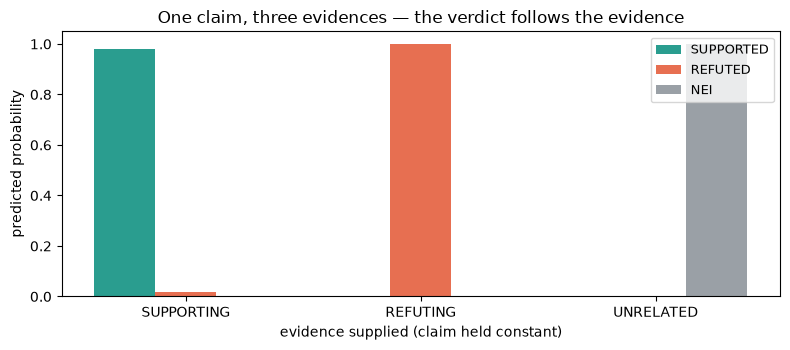

In [8]:
df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(df)); w = 0.26
colours = {"SUPPORTED": "#2a9d8f", "REFUTED": "#e76f51", "NEI": "#9aa0a6"}
for i, l in enumerate(LABELS):
    ax.bar(x + (i - 1) * w, df[l], w, label=l, color=colours[l])
ax.set_xticks(x); ax.set_xticklabels(df["evidence supplied"])
ax.set_xlabel("evidence supplied (claim held constant)")
ax.set_ylabel("predicted probability"); ax.set_ylim(0, 1.05)
ax.set_title("One claim, three evidences — the verdict follows the evidence")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()